# ERST619 Assessment 3 — Random Forest Classification

### 2024 Port Hills Fire

This notebook uses **20 m Sentinel-2 pixel samples** prepared in ArcGIS Pro.

Classes:

1. Burned  
2. Unburned  
3. Man-made  
4. Mixed

Predictor variables:

- B2 Blue
- B3 Green
- B4 Red
- B8 NIR
- B11 SWIR1
- B12 SWIR2
- NDVI
- dNBR

The workflow uses a **separate training CSV and validation CSV** so that validation data are not used during model fitting.


## 1. Imports

Run this cell first.  
This notebook uses pandas, NumPy, matplotlib and scikit-learn.


In [1]:

import sys
import sklearn
import numpy
import pandas
import matplotlib
import scipy
import rasterio

print("Python:", sys.version.split()[0])
print("scikit-learn:", sklearn.__version__)
print("NumPy:", numpy.__version__)
print("pandas:", pandas.__version__)
print("Matplotlib:", matplotlib.__version__)
print("SciPy:", scipy.__version__)
print("Rasterio:", rasterio.__version__)


Python: 3.12.10
scikit-learn: 1.9.0
NumPy: 2.5.2
pandas: 3.0.5
Matplotlib: 3.11.1
SciPy: 1.18.1
Rasterio: 1.5.1


In [2]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

# Fixed seed for reproducible results
random.seed(42)
np.random.seed(42)

print("Imports successful.")


Imports successful.


## 2. Input data

Place the two CSV files in the same folder as this notebook, or replace the paths below with full paths.

- `Training_Pixels_20m.csv`
- `Validation_Pixels_20m.csv`


In [3]:
TRAIN_CSV = "Training_Pixels_20m.csv"
VALID_CSV = "Validation_Pixels_20m.csv"

FEATURES = [
    "B2",
    "B3",
    "B4",
    "B8",
    "B11",
    "B12",
    "NDVI",
    "dNBR"
]

TARGET = "Class_Name"

CLASS_ORDER = [
    "Burned",
    "Unburned",
    "Man-made",
    "Mixed"
]

print("Predictors:", FEATURES)
print("Target:", TARGET)


Predictors: ['B2', 'B3', 'B4', 'B8', 'B11', 'B12', 'NDVI', 'dNBR']
Target: Class_Name


## 3. Read the training and validation data

Each row represents one **20 m × 20 m Sentinel-2 pixel**.

The code checks that all required predictor fields and the class field are present.


In [4]:
train_df = pd.read_csv(TRAIN_CSV)
valid_df = pd.read_csv(VALID_CSV)

required = set(FEATURES + [TARGET])

missing_train = required.difference(train_df.columns)
missing_valid = required.difference(valid_df.columns)

if missing_train:
    raise ValueError(f"Training CSV is missing field(s): {missing_train}")

if missing_valid:
    raise ValueError(f"Validation CSV is missing field(s): {missing_valid}")

print("Training rows:", len(train_df))
print("Validation rows:", len(valid_df))

print("\nTraining columns:")
print(train_df.columns.tolist())

print("\nValidation columns:")
print(valid_df.columns.tolist())


Training rows: 1013
Validation rows: 479

Training columns:
['OBJECTID', 'pointid', 'grid_code', 'dNBR', 'NDVI', 'B12', 'B11', 'B8', 'B4', 'B3', 'B2', 'Class_Name']

Validation columns:
['OBJECTID', 'pointid', 'grid_code', 'dNBR', 'NDVI', 'B12', 'B11', 'B8', 'B4', 'B3', 'B2', 'Class_Name']


## 4. Remove missing or non-finite values

Only rows containing valid values for all 8 predictors and the class label are retained.


In [5]:
train_model = train_df[FEATURES + [TARGET]].copy()
valid_model = valid_df[FEATURES + [TARGET]].copy()

# Convert predictors to numeric
for col in FEATURES:
    train_model[col] = pd.to_numeric(train_model[col], errors="coerce")
    valid_model[col] = pd.to_numeric(valid_model[col], errors="coerce")

# Replace inf values with NaN, then remove incomplete rows
train_model = train_model.replace([np.inf, -np.inf], np.nan).dropna()
valid_model = valid_model.replace([np.inf, -np.inf], np.nan).dropna()

print("Training samples after cleaning:", len(train_model))
print("Validation samples after cleaning:", len(valid_model))


Training samples after cleaning: 1013
Validation samples after cleaning: 479


## 5. Check class distribution

The four training classes should be reasonably balanced.

The validation set remains independent and is used only after training.


Training class counts:
Class_Name
Burned      266
Man-made    251
Mixed       249
Unburned    247
Name: count, dtype: int64

Validation class counts:
Class_Name
Mixed       150
Burned      116
Unburned    109
Man-made    104
Name: count, dtype: int64


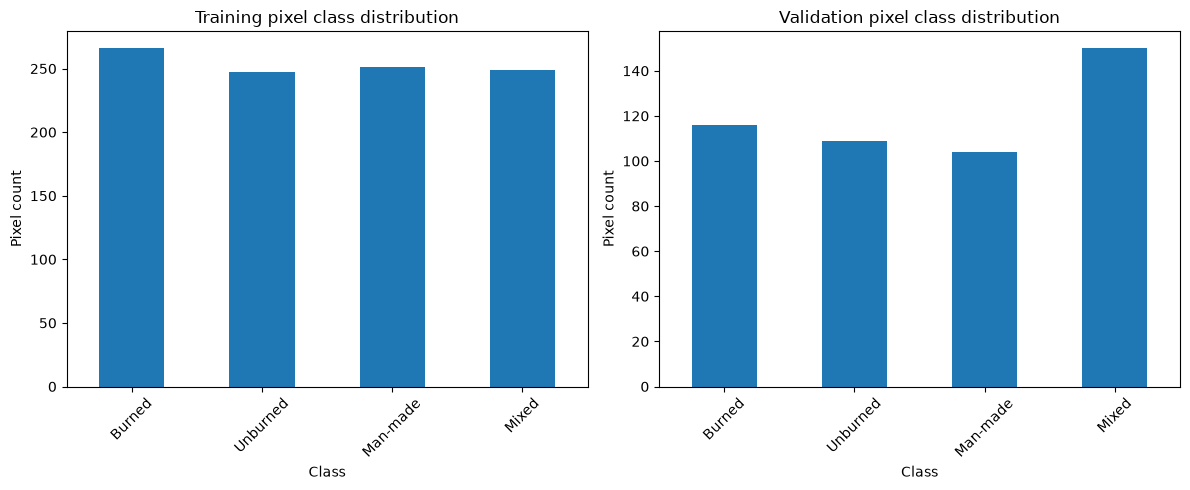

In [6]:
print("Training class counts:")
print(train_model[TARGET].value_counts())

print("\nValidation class counts:")
print(valid_model[TARGET].value_counts())

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

train_model[TARGET].value_counts().reindex(CLASS_ORDER).plot(
    kind="bar",
    ax=axes[0]
)
axes[0].set_title("Training pixel class distribution")
axes[0].set_xlabel("Class")
axes[0].set_ylabel("Pixel count")
axes[0].tick_params(axis="x", rotation=45)

valid_model[TARGET].value_counts().reindex(CLASS_ORDER).plot(
    kind="bar",
    ax=axes[1]
)
axes[1].set_title("Validation pixel class distribution")
axes[1].set_xlabel("Class")
axes[1].set_ylabel("Pixel count")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()


## 6. Compare mean spectral signatures

This reproduces the class-separability idea used in ArcGIS Pro, using the six original Sentinel-2 bands.

NDVI and dNBR are excluded from this spectral-profile plot because they are indices with a different scale.


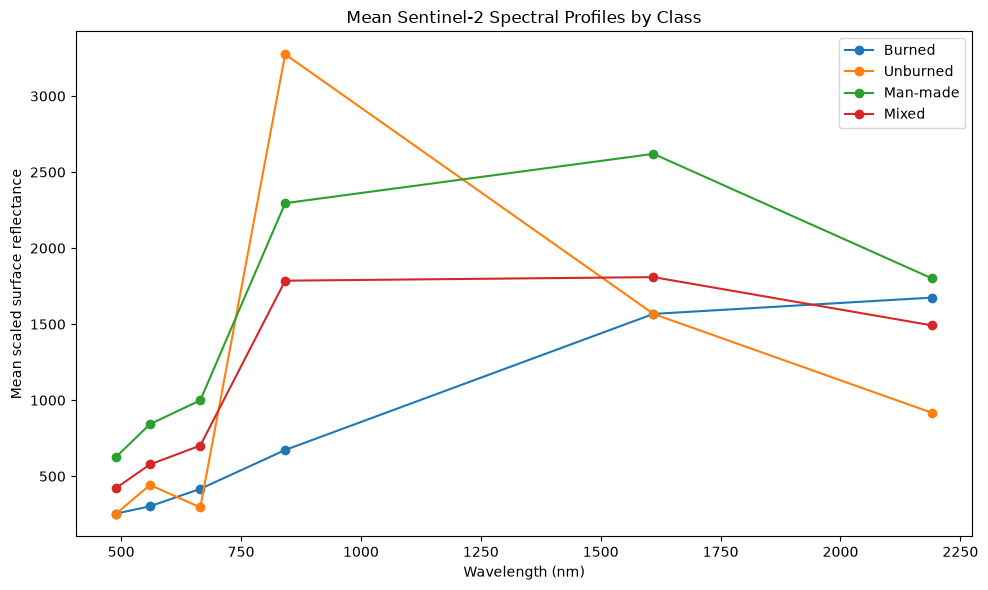

In [7]:
SPECTRAL_FEATURES = ["B2", "B3", "B4", "B8", "B11", "B12"]
WAVELENGTHS = [490, 560, 665, 842, 1610, 2190]

plt.figure(figsize=(10, 6))

for class_name in CLASS_ORDER:
    subset = train_model[train_model[TARGET] == class_name]
    means = subset[SPECTRAL_FEATURES].mean().values

    plt.plot(
        WAVELENGTHS,
        means,
        marker="o",
        label=class_name
    )

plt.title("Mean Sentinel-2 Spectral Profiles by Class")
plt.xlabel("Wavelength (nm)")
plt.ylabel("Mean scaled surface reflectance")
plt.legend()
plt.tight_layout()
plt.show()


## 7. Prepare Random Forest inputs

The training CSV is used to fit the model.

The validation CSV is kept completely separate and is used only for independent accuracy assessment.


In [8]:
X_train = train_model[FEATURES]
y_train = train_model[TARGET]

X_valid = valid_model[FEATURES]
y_valid = valid_model[TARGET]

print("X_train shape:", X_train.shape)
print("X_valid shape:", X_valid.shape)

print("\nTraining classes:")
print(sorted(y_train.unique()))

print("\nValidation classes:")
print(sorted(y_valid.unique()))


X_train shape: (1013, 8)
X_valid shape: (479, 8)

Training classes:
['Burned', 'Man-made', 'Mixed', 'Unburned']

Validation classes:
['Burned', 'Man-made', 'Mixed', 'Unburned']


## 8. Train the Random Forest

`n_estimators=300` means the classifier uses 300 decision trees.

`random_state=42` fixes the random seed so results are reproducible.

Because the four training classes are already close in sample size, no class weighting is required for the first model.


In [9]:
rf = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

print("Random Forest training completed.")


Random Forest training completed.


## 9. Independent validation

The trained model predicts the separate validation pixels.

This section reports:

- Overall accuracy
- Weighted precision
- Weighted recall
- Weighted F1 score
- Confusion matrix
- Per-class precision / recall / F1


In [10]:
y_pred = rf.predict(X_valid)

accuracy = accuracy_score(y_valid, y_pred)
precision = precision_score(
    y_valid, y_pred,
    average="weighted",
    zero_division=0
)
recall = recall_score(
    y_valid, y_pred,
    average="weighted",
    zero_division=0
)
f1 = f1_score(
    y_valid, y_pred,
    average="weighted",
    zero_division=0
)

print(f"Overall Accuracy: {accuracy:.3f} ({accuracy * 100:.2f}%)")
print(f"Weighted Precision: {precision:.3f}")
print(f"Weighted Recall:    {recall:.3f}")
print(f"Weighted F1 Score:  {f1:.3f}")

print("\nClassification report:")
print(
    classification_report(
        y_valid,
        y_pred,
        labels=CLASS_ORDER,
        digits=3,
        zero_division=0
    )
)


Overall Accuracy: 0.566 (56.58%)
Weighted Precision: 0.641
Weighted Recall:    0.566
Weighted F1 Score:  0.559

Classification report:
              precision    recall  f1-score   support

      Burned      0.781     0.767     0.774       116
    Unburned      0.475     0.532     0.502       109
    Man-made      0.935     0.279     0.430       104
       Mixed      0.448     0.633     0.525       150

    accuracy                          0.566       479
   macro avg      0.660     0.553     0.558       479
weighted avg      0.641     0.566     0.559       479



## 10. Confusion matrix

Rows are **reference / actual classes**.

Columns are **Random Forest predictions**.

This helps identify which classes are being confused, especially:

- Burned vs Mixed
- Mixed vs Unburned
- Man-made vs Mixed


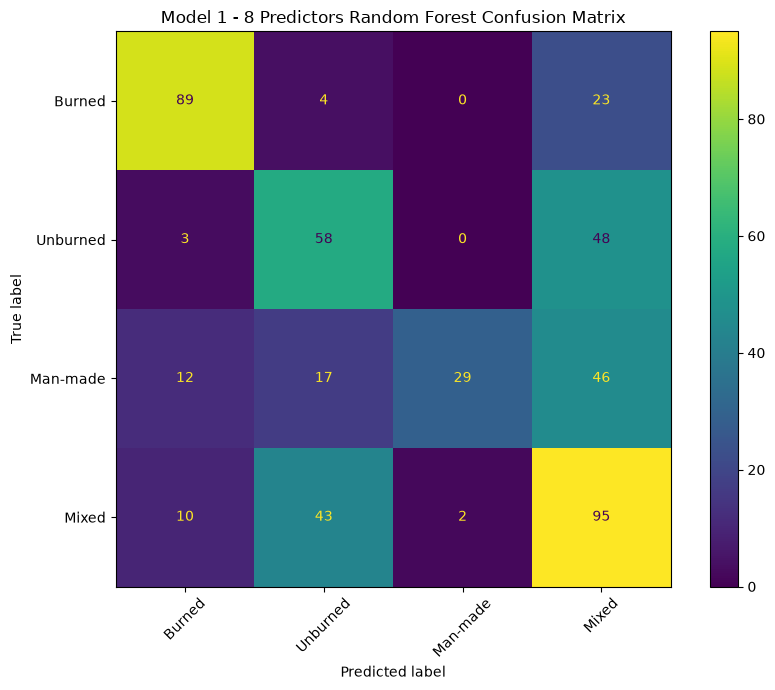

,Predicted_Burned,Predicted_Unburned,Predicted_Man-made,Predicted_Mixed
Reference_Burned,89,4,0,23
Reference_Unburned,3,58,0,48
Reference_Man-made,12,17,29,46
Reference_Mixed,10,43,2,95


In [11]:
cm = confusion_matrix(
    y_valid,
    y_pred,
    labels=CLASS_ORDER
)

fig, ax = plt.subplots(figsize=(9, 7))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=CLASS_ORDER
).plot(
    ax=ax,
    xticks_rotation=45,
    values_format="d"
)

plt.title("Model 1 - 8 Predictors Random Forest Confusion Matrix")
plt.tight_layout()
plt.show()

cm_df = pd.DataFrame(
    cm,
    index=[f"Reference_{c}" for c in CLASS_ORDER],
    columns=[f"Predicted_{c}" for c in CLASS_ORDER]
)

display(cm_df)


## 11. Producer's and User's Accuracy

For each class:

- **Producer's Accuracy** = correctly classified reference pixels / all reference pixels in that class
- **User's Accuracy** = correctly classified pixels / all pixels predicted as that class


In [12]:
diag = np.diag(cm)

producer_accuracy = np.divide(
    diag,
    cm.sum(axis=1),
    out=np.zeros_like(diag, dtype=float),
    where=cm.sum(axis=1) != 0
)

user_accuracy = np.divide(
    diag,
    cm.sum(axis=0),
    out=np.zeros_like(diag, dtype=float),
    where=cm.sum(axis=0) != 0
)

class_accuracy = pd.DataFrame({
    "Class": CLASS_ORDER,
    "Producer_Accuracy_%": producer_accuracy * 100,
    "User_Accuracy_%": user_accuracy * 100
})

display(class_accuracy.round(2))


,Class,Producer_Accuracy_%,User_Accuracy_%
0,Burned,76.72,78.07
1,Unburned,53.21,47.54
2,Man-made,27.88,93.55
3,Mixed,63.33,44.81


## 12. Feature importance

Random Forest feature importance indicates which predictors contribute most strongly to the classification.

For this project, it is especially useful to compare the contribution of:

- dNBR
- NDVI
- B8
- B11
- B12
- visible bands


,Feature,Importance
0,dNBR,0.214848
1,B8,0.161774
2,NDVI,0.141204
3,B4,0.123151
4,B12,0.095272
5,B11,0.092925
6,B2,0.090196
7,B3,0.080630


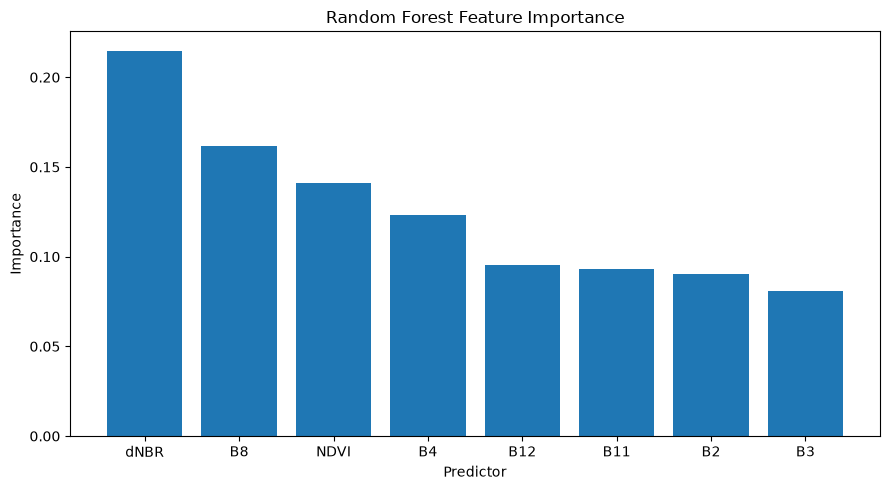

In [13]:
importance = pd.DataFrame({
    "Feature": FEATURES,
    "Importance": rf.feature_importances_
}).sort_values(
    "Importance",
    ascending=False
).reset_index(drop=True)

display(importance)

plt.figure(figsize=(9, 5))
plt.bar(importance["Feature"], importance["Importance"])
plt.title("Random Forest Feature Importance")
plt.xlabel("Predictor")
plt.ylabel("Importance")
plt.tight_layout()
plt.show()


## 13. Save validation results

These CSV outputs can be used directly in Assessment 3 tables and figures.


In [14]:
cm_df.to_csv("RF_confusion_matrix.csv", index=True)
class_accuracy.to_csv("RF_class_accuracy.csv", index=False)
importance.to_csv("RF_feature_importance.csv", index=False)

validation_predictions = valid_model.copy()
validation_predictions["Predicted_Class"] = y_pred
validation_predictions["Correct"] = (
    validation_predictions[TARGET] ==
    validation_predictions["Predicted_Class"]
)

validation_predictions.to_csv(
    "RF_validation_predictions.csv",
    index=False
)

print("Saved:")
print("- RF_confusion_matrix.csv")
print("- RF_class_accuracy.csv")
print("- RF_feature_importance.csv")
print("- RF_validation_predictions.csv")


Saved:
- RF_confusion_matrix.csv
- RF_class_accuracy.csv
- RF_feature_importance.csv
- RF_validation_predictions.csv


## 14. Key takeaways

After running the notebook, record:

1. Overall validation accuracy.
2. Which classes have the highest and lowest Producer's Accuracy.
3. Which classes have the highest and lowest User's Accuracy.
4. The main class confusions shown by the confusion matrix.
5. Which predictor variables have the highest Random Forest importance.
6. Whether the results support keeping all eight predictor variables.

The independent validation data should **not** be moved into the training data after seeing the classification results.


Model 2 training completed.
Model 1 Overall Accuracy:
0.5658 (56.58%)

Model 2 Overall Accuracy:
0.5699 (56.99%)


,Predicted_Burned,Predicted_Unburned,Predicted_Man-made,Predicted_Mixed
Reference_Burned,92,3,0,21
Reference_Unburned,3,59,0,47
Reference_Man-made,13,16,28,47
Reference_Mixed,8,45,3,94


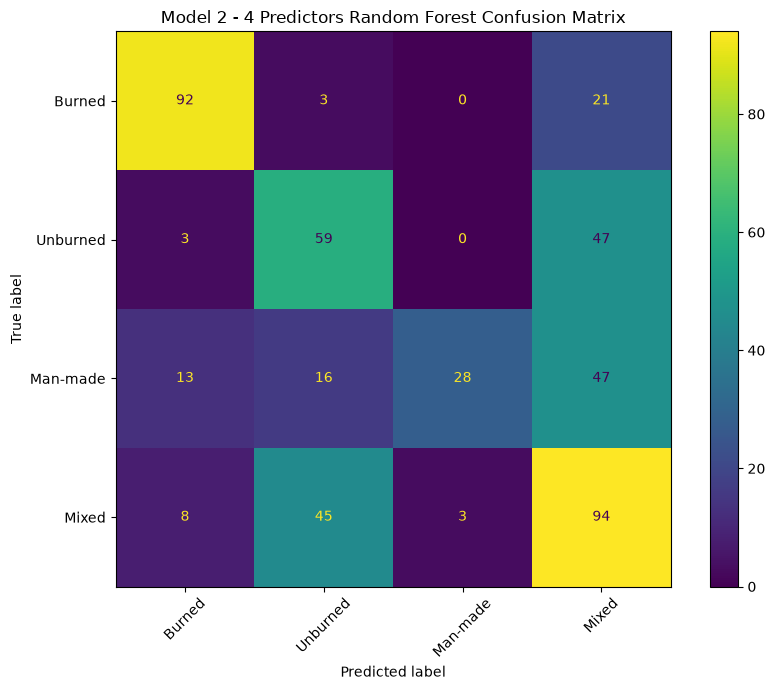

,Class,Producer_Accuracy_%,User_Accuracy_%
0,Burned,79.31,79.31
1,Unburned,54.13,47.97
2,Man-made,26.92,90.32
3,Mixed,62.67,44.98


,Model,Overall_Accuracy_%
0,Model 1 - 8 Predictors,56.58
1,Model 2 - 4 Predictors,56.99


In [15]:
MODEL2_FEATURES = [
    "dNBR",
    "B8",
    "NDVI",
    "B4"
]
# ============================================================
# Model 2: Reduced predictor Random Forest
# Predictors: dNBR, B8, NDVI, B4
# ============================================================

MODEL2_FEATURES = [
    "dNBR",
    "B8",
    "NDVI",
    "B4"
]

X_train_m2 = train_model[MODEL2_FEATURES]
X_valid_m2 = valid_model[MODEL2_FEATURES]

rf_model2 = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

rf_model2.fit(X_train_m2, y_train)

y_pred_m2 = rf_model2.predict(X_valid_m2)

print("Model 2 training completed.")
accuracy_m2 = accuracy_score(y_valid, y_pred_m2)

print("Model 1 Overall Accuracy:")
print(f"{accuracy:.4f} ({accuracy * 100:.2f}%)")

print("\nModel 2 Overall Accuracy:")
print(f"{accuracy_m2:.4f} ({accuracy_m2 * 100:.2f}%)")

cm_m2 = confusion_matrix(
    y_valid,
    y_pred_m2,
    labels=CLASS_ORDER
)

cm_m2_df = pd.DataFrame(
    cm_m2,
    index=[f"Reference_{c}" for c in CLASS_ORDER],
    columns=[f"Predicted_{c}" for c in CLASS_ORDER]
)

display(cm_m2_df)

fig, ax = plt.subplots(figsize=(9, 7))

ConfusionMatrixDisplay(
    confusion_matrix=cm_m2,
    display_labels=CLASS_ORDER
).plot(
    ax=ax,
    xticks_rotation=45,
    values_format="d"
)

plt.title("Model 2 - 4 Predictors Random Forest Confusion Matrix")
plt.tight_layout()
plt.show()

diag_m2 = np.diag(cm_m2)

producer_m2 = np.divide(
    diag_m2,
    cm_m2.sum(axis=1),
    out=np.zeros_like(diag_m2, dtype=float),
    where=cm_m2.sum(axis=1) != 0
)

user_m2 = np.divide(
    diag_m2,
    cm_m2.sum(axis=0),
    out=np.zeros_like(diag_m2, dtype=float),
    where=cm_m2.sum(axis=0) != 0
)

class_accuracy_m2 = pd.DataFrame({
    "Class": CLASS_ORDER,
    "Producer_Accuracy_%": producer_m2 * 100,
    "User_Accuracy_%": user_m2 * 100
})

display(class_accuracy_m2.round(2))

comparison = pd.DataFrame({
    "Model": [
        "Model 1 - 8 Predictors",
        "Model 2 - 4 Predictors"
    ],
    "Overall_Accuracy_%": [
        accuracy * 100,
        accuracy_m2 * 100
    ]
})

display(comparison.round(2))

(1013, 4)
Fitting 5 folds for each of 54 candidates, totalling 270 fits
Best parameters:
{'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 4, 'n_estimators': 200}

Best mean 5-fold CV accuracy:
0.7522
75.22%
RandomForestClassifier(min_samples_leaf=4, n_estimators=200, n_jobs=-1,
                       random_state=42)
Final independent validation accuracy:
0.5678 (56.78%)


,Predicted_Burned,Predicted_Unburned,Predicted_Man-made,Predicted_Mixed
Reference_Burned,91,3,0,22
Reference_Unburned,3,59,0,47
Reference_Man-made,14,15,26,49
Reference_Mixed,8,45,1,96


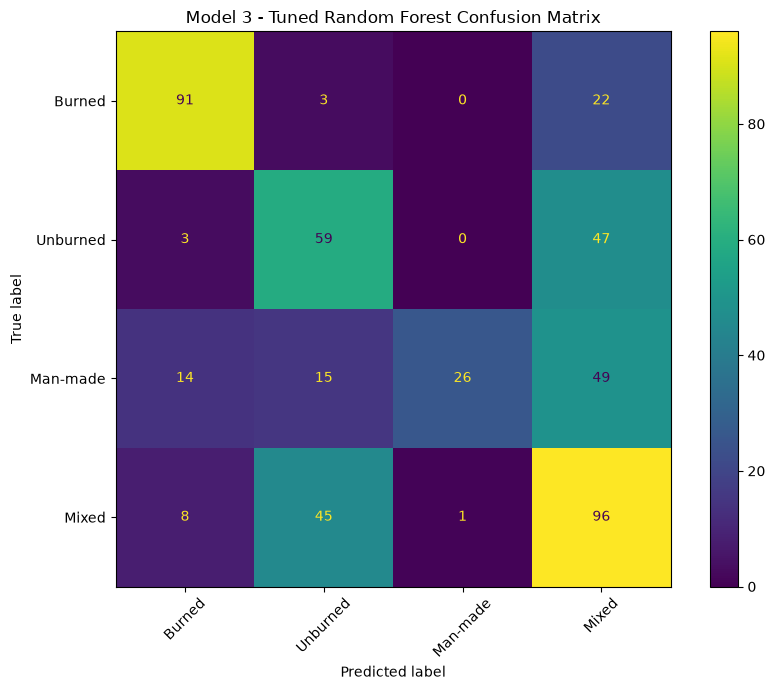

,Model,Validation_Accuracy_%
0,Model 1 - 8 Predictors,56.58
1,Model 2 - 4 Predictors,56.99
2,Model 3 - Tuned RF,56.78


In [16]:
from sklearn.model_selection import GridSearchCV
TUNE_FEATURES = [
    "dNBR",
    "B8",
    "NDVI",
    "B4"
]

X_train_tune = train_model[TUNE_FEATURES]
X_valid_tune = valid_model[TUNE_FEATURES]

print(X_train_tune.shape)
param_grid = {
    "n_estimators": [200, 300, 500],
    "max_depth": [None, 10, 20],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", 0.5]
}
rf_base = RandomForestClassifier(
    random_state=42,
    n_jobs=-1
)

grid_search = GridSearchCV(
    estimator=rf_base,
    param_grid=param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1,
    verbose=1
)

grid_search.fit(
    X_train_tune,
    y_train
)

print("Best parameters:")
print(grid_search.best_params_)

print("\nBest mean 5-fold CV accuracy:")
print(f"{grid_search.best_score_:.4f}")
print(f"{grid_search.best_score_ * 100:.2f}%")

best_rf = grid_search.best_estimator_

print(best_rf)

y_pred_best = best_rf.predict(X_valid_tune)

best_validation_accuracy = accuracy_score(
    y_valid,
    y_pred_best
)

print("Final independent validation accuracy:")
print(
    f"{best_validation_accuracy:.4f} "
    f"({best_validation_accuracy * 100:.2f}%)"
)

cm_best = confusion_matrix(
    y_valid,
    y_pred_best,
    labels=CLASS_ORDER
)

cm_best_df = pd.DataFrame(
    cm_best,
    index=[f"Reference_{c}" for c in CLASS_ORDER],
    columns=[f"Predicted_{c}" for c in CLASS_ORDER]
)

display(cm_best_df)

fig, ax = plt.subplots(figsize=(9, 7))

ConfusionMatrixDisplay(
    confusion_matrix=cm_best,
    display_labels=CLASS_ORDER
).plot(
    ax=ax,
    xticks_rotation=45,
    values_format="d"
)

plt.title("Model 3 - Tuned Random Forest Confusion Matrix")
plt.tight_layout()
plt.show()

model_comparison = pd.DataFrame({
    "Model": [
        "Model 1 - 8 Predictors",
        "Model 2 - 4 Predictors",
        "Model 3 - Tuned RF"
    ],
    "Validation_Accuracy_%": [
        accuracy * 100,
        accuracy_m2 * 100,
        best_validation_accuracy * 100
    ]
})

display(model_comparison.round(2))

In [17]:
RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)
import rasterio
import numpy as np
raster_path = "Port_Hills_Classification_8Bands_2024.tif"

with rasterio.open(raster_path) as src:
    profile = src.profile.copy()

    B4 = src.read(3)
    B8 = src.read(4)
    NDVI = src.read(7)
    dNBR = src.read(8)

print("Raster loaded.")
print("Shape:", B4.shape)
stack = np.stack([
    dNBR,
    B8,
    NDVI,
    B4
], axis=-1)

rows, cols, bands = stack.shape

print(stack.shape)

valid_mask = np.all(np.isfinite(stack), axis=2)

print("Valid pixels:", valid_mask.sum())

X_full = stack[valid_mask]

print("Pixels to classify:", X_full.shape)

MODEL2_FEATURES = [
    "dNBR",
    "B8",
    "NDVI",
    "B4"
]


predicted_classes = rf_model2.predict(X_full)

class_map = {
    "Burned": 1,
    "Unburned": 2,
    "Man-made": 3,
    "Mixed": 4
}

predicted_codes = np.array(
    [class_map[x] for x in predicted_classes],
    dtype=np.uint8
)

classified = np.zeros(
    (rows, cols),
    dtype=np.uint8
)

classified[valid_mask] = predicted_codes

output_path = "Port_Hills_RF_Classification.tif"

profile.update(
    count=1,
    dtype=rasterio.uint8,
    nodata=0
)

with rasterio.open(
    output_path,
    "w",
    **profile
) as dst:
    dst.write(classified, 1)

print("Classification saved:")
print(output_path)

Raster loaded.
Shape: (203, 211)
(203, 211, 4)
Valid pixels: 42548
Pixels to classify: (42548, 4)


d:\619\Lab06_SupervisedClass\venv\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


Classification saved:
Port_Hills_RF_Classification.tif


In [18]:
import rasterio
import numpy as np
import pandas as pd
from scipy.stats import skew, kurtosis

rasters = {
    "B2": "B2_20m.tif",
    "B3": "B3_20m.tif",
    "B4": "B4_20m.tif",
    "B8": "B8_20m.tif",
    "B11": "B11_20m.tif",
    "B12": "B12_20m.tif",
    "NDVI": "NDVI_20m.tif",
    "dNBR": "dNBR_20m.tif"
}

results = []

for name, path in rasters.items():

    with rasterio.open(path) as src:
        data = src.read(1).astype(float)

        # Remove NoData
        if src.nodata is not None:
            data[data == src.nodata] = np.nan

    # Keep only finite values
    values = data[np.isfinite(data)]

    results.append({
        "Variable": name,
        "Mean": np.mean(values),
        "Standard_Deviation": np.std(values, ddof=1),
        "Skewness": skew(values, bias=False),
        "Kurtosis": kurtosis(values, fisher=True, bias=False)
    })

stats_table = pd.DataFrame(results)

display(stats_table.round(3))

stats_table.to_csv(
    "Raster_Distribution_Statistics.csv",
    index=False
)

print("Saved: Raster_Distribution_Statistics.csv")

,Variable,Mean,Standard_Deviation,Skewness,Kurtosis
0,B2,337.855,193.291,1.466,6.164
1,B3,510.875,240.260,1.006,2.250
2,B4,535.258,345.594,0.780,0.016
3,B8,2377.823,1192.401,0.717,0.591
4,B11,1860.790,705.480,0.458,-0.122
5,B12,1249.300,658.913,0.497,-0.551
6,NDVI,0.577,0.272,-0.447,0.012
7,dNBR,0.283,0.280,0.998,0.061


Saved: Raster_Distribution_Statistics.csv


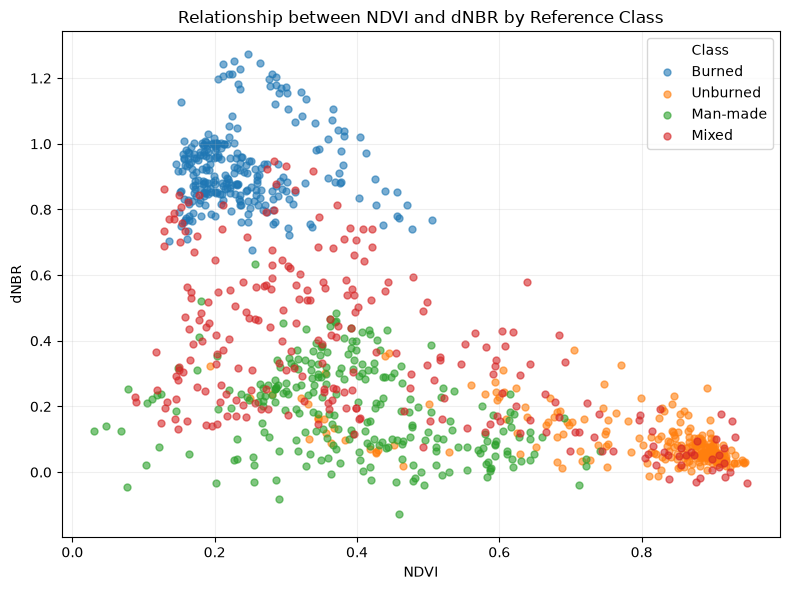

In [19]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

for class_name in CLASS_ORDER:
    subset = train_model[train_model["Class_Name"] == class_name]

    plt.scatter(
        subset["NDVI"],
        subset["dNBR"],
        label=class_name,
        alpha=0.6,
        s=25
    )

plt.xlabel("NDVI")
plt.ylabel("dNBR")
plt.title("Relationship between NDVI and dNBR by Reference Class")
plt.legend(title="Class")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [20]:
relationship_stats = (
    train_model
    .groupby("Class_Name")[["NDVI", "dNBR", "B8"]]
    .agg(["mean", "std"])
    .round(3)
)

display(relationship_stats)

NDVI          dNBR               B8          
             mean    std   mean    std      mean       std
Class_Name                                                
Burned      0.238  0.073  0.923  0.118   672.549   139.975
Man-made    0.396  0.139  0.187  0.137  2295.685   421.331
Mixed       0.416  0.237  0.370  0.240  1785.888   757.410
Unburned    0.796  0.163  0.095  0.074  3274.526  1553.433

In [21]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

REG_FEATURES = ["NDVI", "dNBR", "B8"]

X_train_reg = train_model[REG_FEATURES]
X_valid_reg = valid_model[REG_FEATURES]

y_train_reg = train_model["Class_Name"]
y_valid_reg = valid_model["Class_Name"]

log_reg = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

log_reg.fit(X_train_reg, y_train_reg)

y_pred_reg = log_reg.predict(X_valid_reg)

reg_accuracy = accuracy_score(
    y_valid_reg,
    y_pred_reg
)

print("Multinomial Logistic Regression Accuracy:")
print(f"{reg_accuracy:.4f} ({reg_accuracy * 100:.2f}%)")

print("\nClassification Report:")
print(
    classification_report(
        y_valid_reg,
        y_pred_reg,
        zero_division=0
    )
)

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_valid_reg,
        y_pred_reg,
        labels=CLASS_ORDER
    )
)

Multinomial Logistic Regression Accuracy:
0.5846 (58.46%)

Classification Report:
              precision    recall  f1-score   support

      Burned       0.75      0.81      0.78       116
    Man-made       0.73      0.37      0.49       104
       Mixed       0.45      0.49      0.47       150
    Unburned       0.54      0.69      0.60       109

    accuracy                           0.58       479
   macro avg       0.62      0.59      0.58       479
weighted avg       0.60      0.58      0.58       479


Confusion Matrix:
[[94  3  0 19]
 [ 3 75  0 31]
 [15 12 38 39]
 [13 50 14 73]]
